# Assignment 3 - CNN (MNIST)
**Offline version** - runs without internet.
Needs `mnist.npz` in the same folder (see `00_download_once.ipynb`).

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import os

tf.random.set_seed(42)
np.random.seed(42)

print("All libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

All libraries imported successfully!
TensorFlow Version: 2.22.0-rc0


In [3]:
def load_mnist(path="mnist.npz"):
    for p in (path, os.path.expanduser("~/.keras/datasets/mnist.npz")):
        if os.path.exists(p):
            with np.load(p, allow_pickle=True) as f:
                return (f["x_train"], f["y_train"]), (f["x_test"], f["y_test"])

    raise FileNotFoundError("mnist.npz not found. Put it in the notebook folder.")

(x_train, y_train), (x_test, y_test) = load_mnist()

print("MNIST Dataset Loaded Successfully!")
print("Training Images:", x_train.shape)
print("Testing Images:", x_test.shape)

MNIST Dataset Loaded Successfully!
Training Images: (60000, 28, 28)
Testing Images: (10000, 28, 28)


In [4]:
x_train = x_train.astype("float32")[..., None] / 255.0
x_test = x_test.astype("float32")[..., None] / 255.0

print("Training Shape:", x_train.shape)
print("Testing Shape:", x_test.shape)

Training Shape: (60000, 28, 28, 1)
Testing Shape: (10000, 28, 28, 1)


In [5]:
y_train_c = keras.utils.to_categorical(y_train, 10)
y_test_c = keras.utils.to_categorical(y_test, 10)

print("One-Hot Encoding Completed!")
print("Training Labels:", y_train_c.shape)
print("Testing Labels:", y_test_c.shape)

One-Hot Encoding Completed!
Training Labels: (60000, 10)
Testing Labels: (10000, 10)


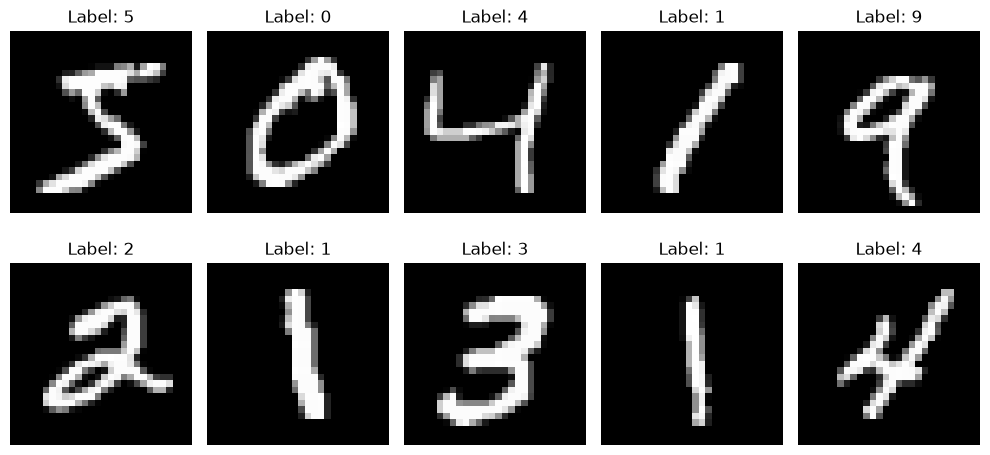

In [6]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i, :, :, 0], cmap="gray")
    plt.title("Label: " + str(y_train[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),

    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dropout(0.5),

    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │          16,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN Model Compiled Successfully!")

CNN Model Compiled Successfully!


In [9]:
H = model.fit(
    x_train,
    y_train_c,
    batch_size=128,
    epochs=10,
    validation_split=0.1,
    verbose=2
)

Epoch 1/10
422/422 - 7s - 16ms/step - accuracy: 0.8877 - loss: 0.3672 - val_accuracy: 0.9788 - val_loss: 0.0818
Epoch 2/10
422/422 - 5s - 12ms/step - accuracy: 0.9646 - loss: 0.1149 - val_accuracy: 0.9847 - val_loss: 0.0570
Epoch 3/10
422/422 - 5s - 12ms/step - accuracy: 0.9747 - loss: 0.0843 - val_accuracy: 0.9873 - val_loss: 0.0468
Epoch 4/10
422/422 - 5s - 12ms/step - accuracy: 0.9783 - loss: 0.0715 - val_accuracy: 0.9878 - val_loss: 0.0444
Epoch 5/10
422/422 - 5s - 12ms/step - accuracy: 0.9806 - loss: 0.0630 - val_accuracy: 0.9885 - val_loss: 0.0391
Epoch 6/10
422/422 - 5s - 12ms/step - accuracy: 0.9827 - loss: 0.0577 - val_accuracy: 0.9900 - val_loss: 0.0352
Epoch 7/10
422/422 - 5s - 12ms/step - accuracy: 0.9845 - loss: 0.0504 - val_accuracy: 0.9908 - val_loss: 0.0338
Epoch 8/10
422/422 - 5s - 12ms/step - accuracy: 0.9851 - loss: 0.0474 - val_accuracy: 0.9908 - val_loss: 0.0338
Epoch 9/10
422/422 - 5s - 12ms/step - accuracy: 0.9864 - loss: 0.0444 - val_accuracy: 0.9907 - val_loss:

In [10]:
loss, acc = model.evaluate(x_test, y_test_c, verbose=0)

print("Test Loss:", round(loss, 4))
print("Test Accuracy:", round(acc, 4))
print("Accuracy Percentage:", round(acc * 100, 2), "%")

Test Loss: 0.0254
Test Accuracy: 0.9917
Accuracy Percentage: 99.17 %


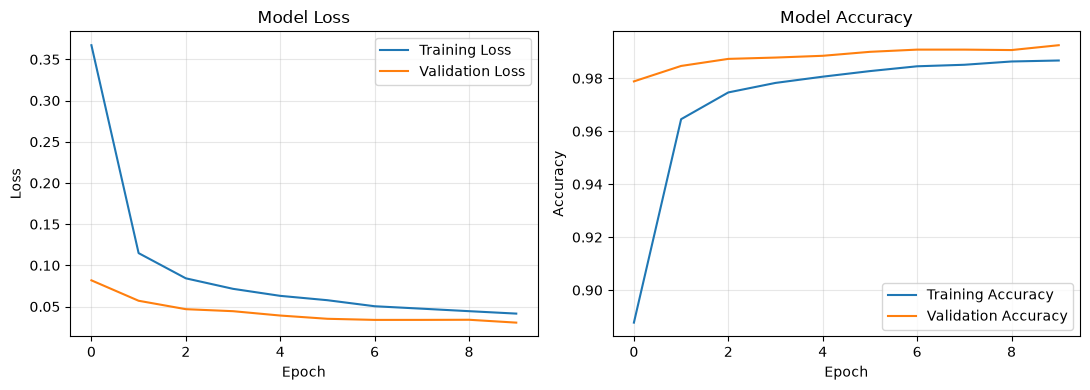

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Loss Graph
ax[0].plot(H.history["loss"], label="Training Loss")
ax[0].plot(H.history["val_loss"], label="Validation Loss")
ax[0].set_title("Model Loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].legend()
ax[0].grid(alpha=0.3)

# Accuracy Graph
ax[1].plot(H.history["accuracy"], label="Training Accuracy")
ax[1].plot(H.history["val_accuracy"], label="Validation Accuracy")
ax[1].set_title("Model Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("a3_curves.png", dpi=130)
plt.show()

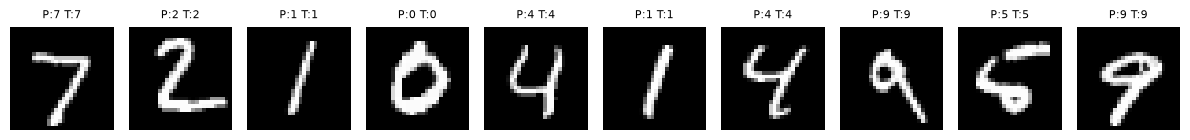

In [13]:
pred = model.predict(x_test[:10], verbose=0).argmax(axis=1)

fig, ax = plt.subplots(1, 10, figsize=(12, 2))

for i in range(10):
    ax[i].imshow(x_test[i, :, :, 0], cmap="gray")
    ax[i].axis("off")
    ax[i].set_title(
        f"P:{pred[i]} T:{y_test[i]}",
        fontsize=8
    )

plt.tight_layout()
plt.savefig("a3_predictions.png", dpi=130)
plt.show()

In [14]:
print("Predicted Labels:", pred.tolist())
print("Actual Labels:   ", y_test[:10].tolist())

Predicted Labels: [7, 2, 1, 0, 4, 1, 4, 9, 5, 9]
Actual Labels:    [7, 2, 1, 0, 4, 1, 4, 9, 5, 9]


In [15]:
model.save("mnist_cnn_model.keras")

print("CNN Model Saved Successfully!")

CNN Model Saved Successfully!
